# 🚗 Análise Exploratória de Dados (EDA): Detecção e Prevenção de Intrusões em Redes CAN
**Projeto CIN0114 — Replicação de Artigo Científico e Otimização para HPC**

> **Artigo Base:**
> *"An Efficient Intrusion Prevention System for CAN: Hindering Cyber-Attacks With a Low-Cost Platform"*  
> Paulo Freitas de Araujo-Filho, Antônio J. Pinheiro, Georges Kaddoum, Divanilson R. Campelo, Fabio L. Soares  
> **IEEE Access**, Vol. 9, 2021. DOI: [10.1109/ACCESS.2021.3136147](https://doi.org/10.1109/ACCESS.2021.3136147)

---

### 🛡️ Princípio Metodológico Fundamental: Isolamento do Conjunto de Teste
Em conformidade com o rigor acadêmico e as boas práticas de Ciência de Dados e Segurança da Informação:
- **A Análise Exploratória (EDA) é realizada ESTRITAMENTE sobre os dados de Treinamento e Validação** (Treino: $225.000$ normais; Validação: $25.000$ normais $+ 25.000$ ataques).
- **O Conjunto de Teste ($>3{,}5$ milhões de frames por dataset) permanece $100\%$ intocado e blindado**, prevenindo qualquer tipo de vazamento de dados (*data leakage*) e garantindo que as métricas de avaliação futura sejam perfeitamente imparciais.
- Todas as operações de leitura, particionamento e validação foram modularizadas no arquivo **`utils.py`**, permitindo reutilização direta tanto neste notebook quanto nos scripts futuros de treinamento e submissão ao cluster.

---

### 🎯 Objetivos deste Notebook
1. **Auditoria e Validação dos Datasets**: Confirmar o alinhamento das contagens brutas com a **Tabela 2** do artigo (3.8M Fuzzy, 4.4M Gear, 4.6M RPM).
2. **Modularização com `utils.py`**: Carregar os dados particionados (Treino/Validação) utilizando o motor centralizado com cache de índices em disco (`.npz`).
3. **Caracterização das Assinaturas nos Dados de Treino e Validação**:
   - **Fuzzing Attack**: injeção de identificadores pseudoaleatórios por todo o espaço de 11 bits (`0x000` a `0x7FF`) e bytes aleatórios.
   - **Drive Gear Spoofing**: injeção direcionada no ID do câmbio (`0x043F`) com payload manipulado.
   - **RPM Gauge Spoofing**: injeção direcionada no ID do tacômetro (`0x0316`) com payload manipulado.
4. **Dinâmica Temporal ($\\Delta t$)**: Contrastar o período estrito de transmissão normal (~10 ms) com as rajadas de injeção em alta frequência (~1.1 ms).
5. **Espaço de Carga Útil ($D_0 \\dots D_7$)**: Fundamentar a razão pela qual utilizar apenas os primeiros $N$ bytes ($N=5$) permite detectar e mitigar intrusões em $<80\\text{ }\\mu\\text{s}$ na Raspberry Pi 4.
6. **Validação Cruzada de 10 Folds**: Demonstrar a partição de folds para a fase de replicação e jobs no cluster HPC.

In [1]:
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Importação do módulo utilitário centralizado do projeto
import utils

# Configuração estética padronizada para relatórios científicos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 14

COLOR_NORMAL = '#1f77b4'   # Azul sóbrio
COLOR_ATTACK = '#d62728'   # Vermelho de alerta
PALETTE = {
    'Normal (R)': COLOR_NORMAL,
    'Ataque (T)': COLOR_ATTACK,
    'Attack (T)': COLOR_ATTACK,
    'Normal': COLOR_NORMAL,
    'Ataque': COLOR_ATTACK,
    'R': COLOR_NORMAL,
    'T': COLOR_ATTACK
}

print(f"Ambiente carregado com sucesso. Python {sys.version.split()[0]}")
print(f"Módulo 'utils' importado de: {os.path.abspath(utils.__file__)}")
for name, p in utils.DATASET_PATHS.items():
    exists = os.path.exists(p)
    size_mb = os.path.getsize(p) / (1024 * 1024) if exists else 0
    print(f" - {name:12s}: {p} ({size_mb:.1f} MB) -> {'Encontrado [OK]' if exists else 'NÃO ENCONTRADO'}")

Ambiente carregado com sucesso. Python 3.14.10
Módulo 'utils' importado de: /home/bruno/Documents/projeto_CIN0114/utils.py
 - Fuzzing     : datasets/Fuzzy_dataset.csv (189.3 MB) -> Encontrado [OK]
 - Drive Gear  : datasets/gear_dataset.csv (219.7 MB) -> Encontrado [OK]
 - RPM Gauge   : datasets/RPM_dataset.csv (228.5 MB) -> Encontrado [OK]
 - Speedometer : datasets/Speedometer_dataset.csv (7.2 MB) -> Encontrado [OK]


### 1. Auditoria Global dos Datasets com o Artigo (Tabela 2)
Antes de isolar os conjuntos, realizamos a auditoria completa do volume bruto para garantir que os arquivos correspondem exatamente aos dados descritos na **Tabela 2 do Artigo (IEEE Access, 2021)**:

| Dataset | # Total de Mensagens | # Mensagens Normais | # Mensagens de Ataque | Proporção de Ataque (%) |
| :--- | :---: | :---: | :---: | :---: |
| **Fuzzing** | 3.838.860 | 3.347.013 | 491.847 | 12,81% |
| **Drive Gear Spoofing** | 4.443.142 | 3.845.890 | 597.252 | 13,44% |
| **RPM Gauge Spoofing** | 4.621.702 | 3.966.805 | 654.897 | 14,17% |

Utilizamos a função `utils.audit_against_paper_table_2()`, que analisa os arquivos via streaming em tempo linear ($O(1)$ de RAM).

In [2]:
print("Executando auditoria global via streaming (utils.audit_against_paper_table_2)...")
t0 = time.time()
df_audit = utils.audit_against_paper_table_2()
print(f"Auditoria concluída em {time.time()-t0:.2f}s!")
display(df_audit)

Executando auditoria global via streaming (utils.audit_against_paper_table_2)...


Auditoria concluída em 37.54s!


,Dataset,Total Auditado,Total Artigo,Normais (R),Normais Artigo,Ataques (T),Ataques Artigo,Taxa Ataque (%),Duração (min),Status
0,Fuzzing,"3,838,860","3,838,860","3,347,013","3,347,013","491,847","491,847",12.81%,91.5,EXATO (100% Match)
1,Drive Gear,"4,443,142","4,443,142","3,845,890","3,845,890","597,252","597,252",13.44%,133.7,EXATO (100% Match)
2,RPM Gauge,"4,621,702","4,621,702","3,966,805","3,966,805","654,897","654,897",14.17%,169.7,EXATO (100% Match)
3,Speedometer,"146,109","146,109","140,337","140,337","5,772","5,772",3.95%,1.4,EXATO (100% Match)


### 2. Protocolo de Particionamento e Carregamento com `utils.py`
Conforme detalhado na metodologia do artigo (Seção V-A):
1. **$250.000$ amostras normais** são selecionadas aleatoriamente por dataset:
   - **Treino ($225.000$ normais, 9 folds)**: Tráfego estritamente legítimo. Modelos de detecção de anomalia (One-Class SVM e Isolation Forest) aprendem exclusivamente a variedade normal do veículo.
   - **Validação ($25.000$ normais, 1 fold)**: Usado para calibração.
2. **$25.000$ amostras maliciosas** são selecionadas aleatoriamente por dataset para compor a validação (totalizando $50.000$ amostras de validação: $50\%$ normais e $50\%$ ataque).
3. **Conjunto de Teste**: Todas as mensagens remanescentes formam o conjunto de teste independente (ex.: $>3{,}0$ milhões normais e $>460$ mil ataques).

#### 🔒 Carregamento dos Dados para EDA:
Para explorar a distribuição de tráfego sem tocar nos dados de teste, utilizamos a função:
```python
utils.load_train_val_data(dataset_name)
```
Essa função carrega especificamente as $250.000$ amostras normais (Treino + Validação) e as $25.000$ amostras de ataque da Validação ($275.000$ frames no total por dataset).

In [3]:
print("Carregando os dados de Treino + Validação via utils.load_train_val_data()...")
print("O conjunto de Teste permanece 100% blindado no disco.\n")

dfs_train_val = {}
splits_info = {}

for name in utils.DATASET_PATHS.keys():
    t_start = time.time()
    # Carrega os índices de partição (com cache .npz em splits_cache/)
    splits = utils.get_split_indices(name, random_state=42)
    splits_info[name] = splits
    
    # Carrega exclusivamente os dados de Treino + Validação (275.000 frames)
    df_tv = utils.load_train_val_data(name, random_state=42)
    dfs_train_val[name] = df_tv
    elapsed = time.time() - t_start
    
    vc = df_tv['Flag'].value_counts().to_dict()
    print(f" -> {name:12s}: {len(df_tv):,} registros em {elapsed:.2f}s | Classes: {vc}")

# Exibe o sumário dos conjuntos gerados
split_summary = []
for name, sp in splits_info.items():
    split_summary.append({
        'Dataset': name,
        'Treino (Normal)': f"{len(sp['train_normal_idx']):,}",
        'Treino (Ataque)': "0 (100% Normal)",
        'Validação (Normal)': f"{len(sp['val_normal_idx']):,}",
        'Validação (Ataque)': f"{len(sp['val_attack_idx']):,}",
        'Validação Total': f"{len(sp['val_indices']):,}",
        'EDA (Treino+Val)': f"{len(sp['train_val_indices']):,}",
        'Teste Blindado': f"{len(sp['test_indices']):,}"
    })

display(pd.DataFrame(split_summary))

Carregando os dados de Treino + Validação via utils.load_train_val_data()...
O conjunto de Teste permanece 100% blindado no disco.



 -> Fuzzing     : 275,000 registros em 2.51s | Classes: {'R': 250000, 'T': 25000}


 -> Drive Gear  : 275,000 registros em 2.69s | Classes: {'R': 250000, 'T': 25000}


 -> RPM Gauge   : 275,000 registros em 2.72s | Classes: {'R': 250000, 'T': 25000}
 -> Speedometer : 27,500 registros em 0.16s | Classes: {'R': 25000, 'T': 2500}


,Dataset,Treino (Normal),Treino (Ataque),Validação (Normal),Validação (Ataque),Validação Total,EDA (Treino+Val),Teste Blindado
0,Fuzzing,"225,000",0 (100% Normal),"25,000","25,000","50,000","275,000","3,476,024"
1,Drive Gear,"225,000",0 (100% Normal),"25,000","25,000","50,000","275,000","4,127,977"
2,RPM Gauge,"225,000",0 (100% Normal),"25,000","25,000","50,000","275,000","4,305,226"
3,Speedometer,"22,500",0 (100% Normal),250,"2,500",500,"27,500","118,046"


### 3. Análise de Identificadores CAN (`CAN ID`) nos Dados de Treino e Validação
O identificador CAN define a função do comando e sua prioridade física no circuito de arbitragem (menor valor hexadecimal = maior prioridade).

Abaixo, examinamos como os identificadores se distribuem entre o tráfego normal (Treino + Validação) e as injeções maliciosas (Validação):
- **Fuzzing Attack**: O invasor gera identificadores pseudoaleatórios com o objetivo de varrer o espaço completo de 11 bits (`0x000` a `0x7FF`). Enquanto a rede normal utiliza apenas ~38 IDs ativos, o ataque injeta em múltiplos IDs distintos.
- **Drive Gear Spoofing**: O invasor ataca especificamente o identificador do câmbio (`0x043F`). $100\%$ dos pacotes maliciosos concentram-se nesse ID.
- **RPM Gauge Spoofing**: O invasor ataca especificamente o identificador do tacômetro (`0x0316`). $100\%$ dos pacotes maliciosos concentram-se nesse ID.

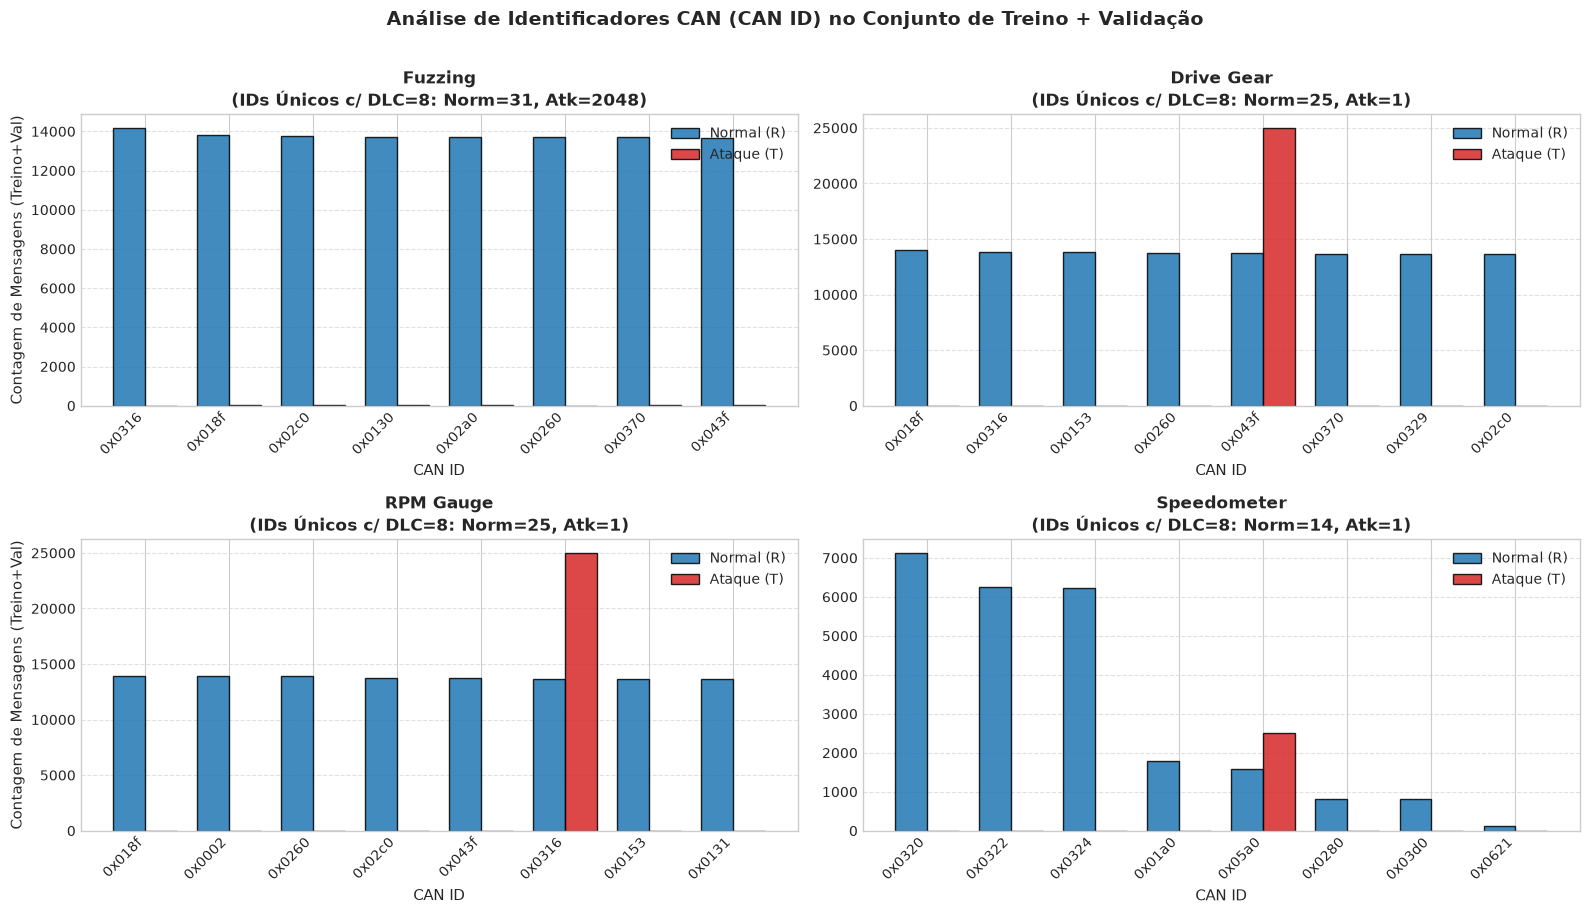

Alvos Específicos Identificados na Validação:
 -> Drive Gear:  100% dos ataques (25,000) direcionados ao ID 0x043f.
 -> RPM Gauge:   100% dos ataques (25,000) direcionados ao ID 0x0316.
 -> Speedometer: 100% dos ataques (2,500) direcionados ao ID 0x05a0 (Painel VW).
 -> Fuzzing:     Ataques distribuídos de forma estocástica por 2048 IDs distintos.


In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()
fig.suptitle('Análise de Identificadores CAN (CAN ID) no Conjunto de Treino + Validação', y=1.01, fontweight='bold')

for i, (name, ax) in enumerate(zip(utils.DATASET_PATHS.keys(), axes)):
    df_tv = dfs_train_val[name]
    
    normal_ids = df_tv[df_tv['Flag'] == 'R']['CAN_ID'].value_counts()
    attack_ids = df_tv[df_tv['Flag'] == 'T']['CAN_ID'].value_counts()
    
    # Top 8 IDs mais frequentes no tráfego normal
    top_ids = list(normal_ids.head(8).index)
    
    # Garante que o alvo de spoofing apareça no gráfico
    target_map = {'Drive Gear': '043f', 'RPM Gauge': '0316', 'Speedometer': '05a0'}
    target_id = target_map.get(name, None)
    if target_id and target_id not in top_ids:
        top_ids.append(target_id)
        
    normal_counts = [normal_ids.get(cid, 0) for cid in top_ids]
    attack_counts = [attack_ids.get(cid, 0) for cid in top_ids]
    
    x = np.arange(len(top_ids))
    width = 0.38
    
    ax.bar(x - width/2, normal_counts, width, label='Normal (R)', color=COLOR_NORMAL, edgecolor='black', alpha=0.85)
    ax.bar(x + width/2, attack_counts, width, label='Ataque (T)', color=COLOR_ATTACK, edgecolor='black', alpha=0.85)
    
    ax.set_xticks(x)
    ax.set_xticklabels([f"0x{cid}" for cid in top_ids], rotation=45, ha='right')
    ax.set_title(f"{name}\n(IDs Únicos c/ DLC=8: Norm={len(normal_ids)}, Atk={len(attack_ids)})", fontweight='bold')
    ax.set_xlabel('CAN ID')
    if i % 2 == 0:
        ax.set_ylabel('Contagem de Mensagens (Treino+Val)')
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

print("Alvos Específicos Identificados na Validação:")
gear_atk_cnt = (dfs_train_val['Drive Gear']['CAN_ID'] == '043f') & (dfs_train_val['Drive Gear']['Flag'] == 'T')
rpm_atk_cnt = (dfs_train_val['RPM Gauge']['CAN_ID'] == '0316') & (dfs_train_val['RPM Gauge']['Flag'] == 'T')
spd_atk_cnt = (dfs_train_val['Speedometer']['CAN_ID'] == '05a0') & (dfs_train_val['Speedometer']['Flag'] == 'T')
print(f" -> Drive Gear:  100% dos ataques ({gear_atk_cnt.sum():,}) direcionados ao ID 0x043f.")
print(f" -> RPM Gauge:   100% dos ataques ({rpm_atk_cnt.sum():,}) direcionados ao ID 0x0316.")
print(f" -> Speedometer: 100% dos ataques ({spd_atk_cnt.sum():,}) direcionados ao ID 0x05a0 (Painel VW).")
print(f" -> Fuzzing:     Ataques distribuídos de forma estocástica por {(dfs_train_val['Fuzzing']['Flag'] == 'T').groupby(dfs_train_val['Fuzzing']['CAN_ID']).any().sum()} IDs distintos.")

### 4. Dinâmica Temporal e Análise da Taxa de Injeção ($\Delta t$)
Em barramentos CAN veiculares, mensagens legítimas periódicas operam com relógios fixos.
No caso dos sensores de câmbio (`0x043F`) e de rotação (`0x0316`), o período nominal é de $10\text{ ms}$ ($100\text{ Hz}$).

Durante os ataques de injeção (*spoofing*), o atacante transmite em alta cadência ($\sim 1.1\text{ ms}$, equivalente a $\sim 900\text{-}1000\text{ Hz}$) para sobrepujar a transmissão das ECUs legítimas.

Abaixo, utilizamos a função utilitária `utils.compute_inter_arrival_times()` sobre os conjuntos de Treino e Validação para contrastar os intervalos de chegada ($\Delta t$).

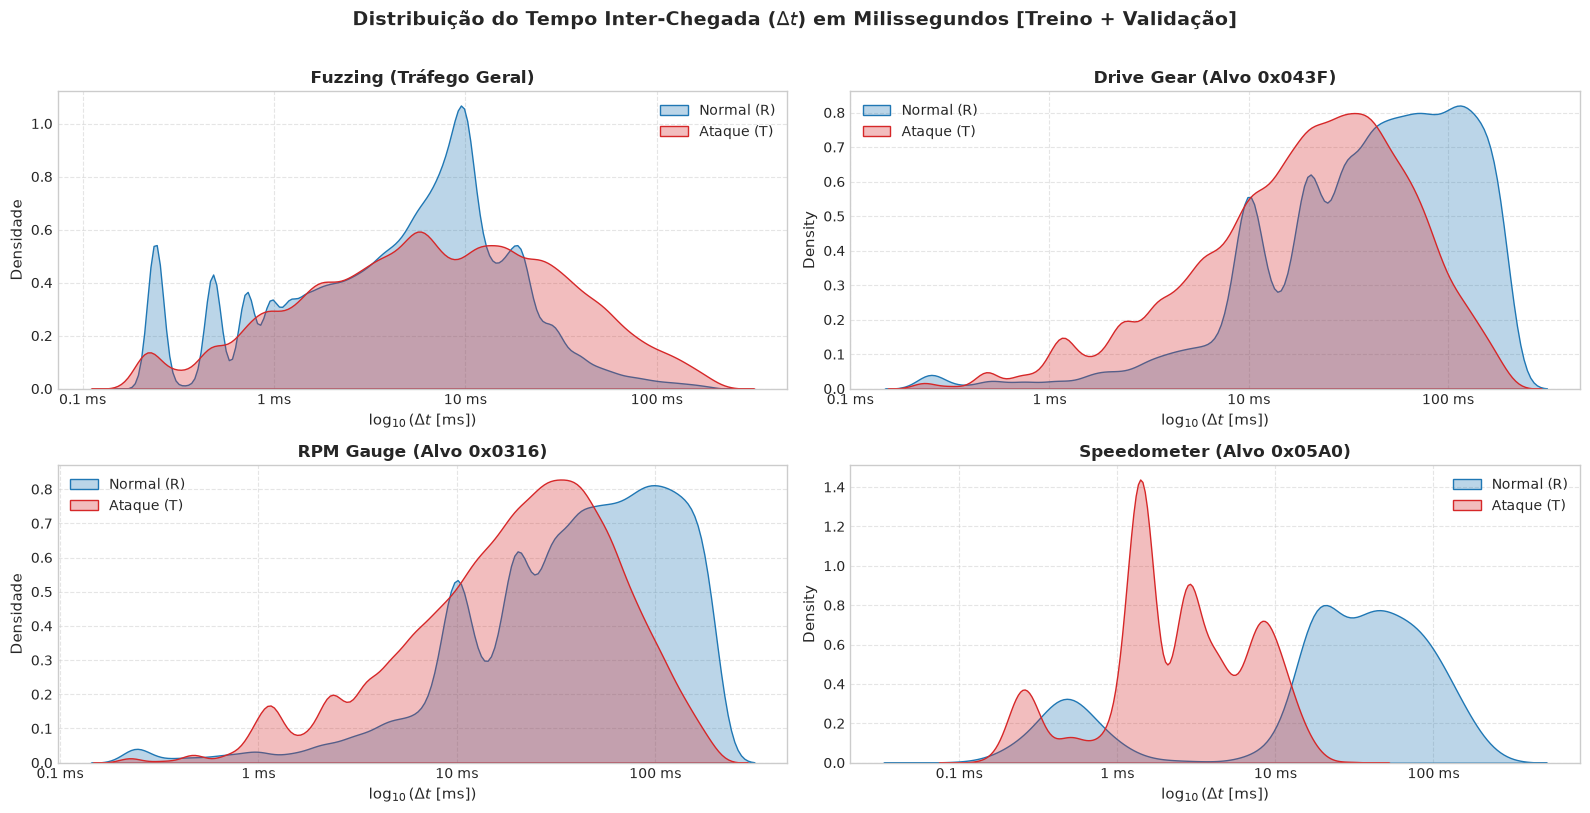

Período Inter-Chegada no Alvo de RPM Gauge (0x0316) em Treino+Validação:
 -> Tráfego Normal (amostrado): Mediana de 60.30 ms
 -> Injeção de Ataque (amostrado): Mediana de 23.06 ms
Período Inter-Chegada no Alvo de Speedometer (0x05a0) em Treino+Validação:
 -> Tráfego Normal (amostrado): Mediana de 36.96 ms
 -> Injeção de Ataque (amostrado): Mediana de 2.67 ms


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
axes = axes.flatten()
fig.suptitle(r'Distribuição do Tempo Inter-Chegada ($\Delta t$) em Milissegundos [Treino + Validação]', y=1.01, fontweight='bold')

targets = [
    ('Fuzzing (Tráfego Geral)', 'Fuzzing', None),
    ('Drive Gear (Alvo 0x043F)', 'Drive Gear', '043f'),
    ('RPM Gauge (Alvo 0x0316)', 'RPM Gauge', '0316'),
    ('Speedometer (Alvo 0x05A0)', 'Speedometer', '05a0')
]

for i, (title, dname, cid) in enumerate(targets):
    ax = axes[i]
    df_temp = utils.compute_inter_arrival_times(dfs_train_val[dname], target_id=cid)
    
    for flag, label, col in [('R', 'Normal (R)', COLOR_NORMAL), ('T', 'Ataque (T)', COLOR_ATTACK)]:
        sub = df_temp[df_temp['Flag'] == flag]['Delta_T_ms'].dropna()
        sub_pos = sub[(sub > 0.05) & (sub < 200.0)]
        if len(sub_pos) > 0:
            sns.kdeplot(np.log10(sub_pos), ax=ax, label=label, color=col, fill=True, alpha=0.3, bw_adjust=0.8)
            
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel(r'$\log_{10}(\Delta t \text{ [ms]})$')
    if i % 2 == 0:
        ax.set_ylabel('Densidade')
    
    ticks = [-1, 0, 1, 2]
    ax.set_xticks(ticks)
    ax.set_xticklabels(['0.1 ms', '1 ms', '10 ms', '100 ms'])
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Mediana do Delta T para RPM e Speedometer
for dname, cid in [('RPM Gauge', '0316'), ('Speedometer', '05a0')]:
    df_t = utils.compute_inter_arrival_times(dfs_train_val[dname], target_id=cid)
    med_norm = df_t[df_t['Flag'] == 'R']['Delta_T_ms'].median()
    med_atk = df_t[df_t['Flag'] == 'T']['Delta_T_ms'].median()
    print(f"Período Inter-Chegada no Alvo de {dname} (0x{cid}) em Treino+Validação:")
    print(f" -> Tráfego Normal (amostrado): Mediana de {med_norm:.2f} ms")
    print(f" -> Injeção de Ataque (amostrado): Mediana de {med_atk:.2f} ms")

### 5. Análise dos Bytes de Carga Útil ($D_0 \dots D_7$) e Normalização
O cerne da proposta científica do artigo é responder:  
*É possível detectar o ataque avaliando apenas os $N$ primeiros bytes do frame ($N \in \{1,\dots,8\}$) antes do encerramento da transmissão física do pacote no barramento?*

Em um barramento CAN padrão a $500\text{ kbps}$, cada bit consome $T_{\text{bit}} = 2\text{ }\mu\text{s}$.
- Para que o IPS envie um quadro de erro CAN a tempo de descartar o frame invasor, a inferência na Raspberry Pi 4 deve ocorrer em menos de $86\text{ }\mu\text{s}$.
- A inferência com $N=5$ bytes consome em média $\sim 78\text{-}79\text{ }\mu\text{s}$ no Isolation Forest (Tabela 8 do artigo), satisfazendo a restrição temporal com acurácia $>99\%$.

Abaixo, inspecionamos os valores médios de cada byte ($D_0 \dots D_7$) em formato decimal ($0$ a $255$) e a versão normalizada dividida por $255.0$ ($[0.0, 1.0]$).

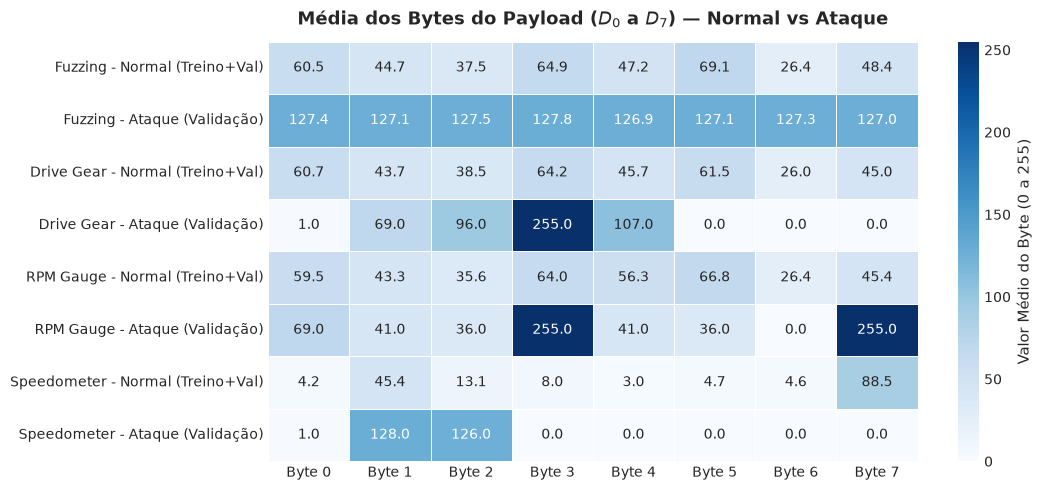

In [6]:
heatmap_rows = []

for name, df_tv in dfs_train_val.items():
    mean_norm = df_tv[df_tv['Flag'] == 'R'][utils.BYTE_COLS].mean().values
    mean_atk = df_tv[df_tv['Flag'] == 'T'][utils.BYTE_COLS].mean().values
    heatmap_rows.append((f"{name} - Normal (Treino+Val)", mean_norm))
    heatmap_rows.append((f"{name} - Ataque (Validação)", mean_atk))

df_heatmap = pd.DataFrame([vals for _, vals in heatmap_rows],
                          index=[lbl for lbl, _ in heatmap_rows],
                          columns=[f"Byte {i}" for i in range(8)])

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(df_heatmap, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': 'Valor Médio do Byte (0 a 255)'}, ax=ax, linewidths=0.5)
ax.set_title(r'Média dos Bytes do Payload ($D_0$ a $D_7$) — Normal vs Ataque', fontsize=13, fontweight='bold', pad=12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 6. Distribuição dos Bytes Individuais: Assinaturas de Ataque
A análise da variabilidade de cada byte ($D_0 \dots D_7$) por meio de gráficos de caixa (*boxplots*) revela os padrões determinísticos injetados pelo invasor:
1. **Fuzzing Attack**: Os bytes $D_0 \dots D_7$ são distribuídos uniformemente entre $0$ e $255$.
2. **Drive Gear Spoofing**: O invasor injeta bytes fixos para enganar a ECU do câmbio (`01 45 60 ff 6b 00 00 00`):
   - $D_0 = 1$ (`0x01` — simula 1ª marcha ou ré forçada), enquanto no normal a média é $\sim 61$.
   - $D_1 = 69$ (`0x45`), $D_2 = 96$ (`0x60`), $D_3 = 255$ (`0xFF`), $D_4 = 107$ (`0x6B`).
   - $D_5, D_6, D_7 = 0$ (`0x00`).
3. **RPM Gauge Spoofing**: O invasor injeta bytes fixos para forçar leitura anormal de giro (`45 29 24 ff 29 24 00 ff`):
   - $D_0 = 69$ (`0x45`), $D_1 = 41$ (`0x29`), $D_2 = 36$ (`0x24`), $D_3 = 255$ (`0xFF`).

Observe que a anomalia é evidente já nos **primeiros bytes**, fundamentando por que $N=5$ (ou menos) atinge acurácia quase perfeita sem precisar aguardar os 8 bytes completos.

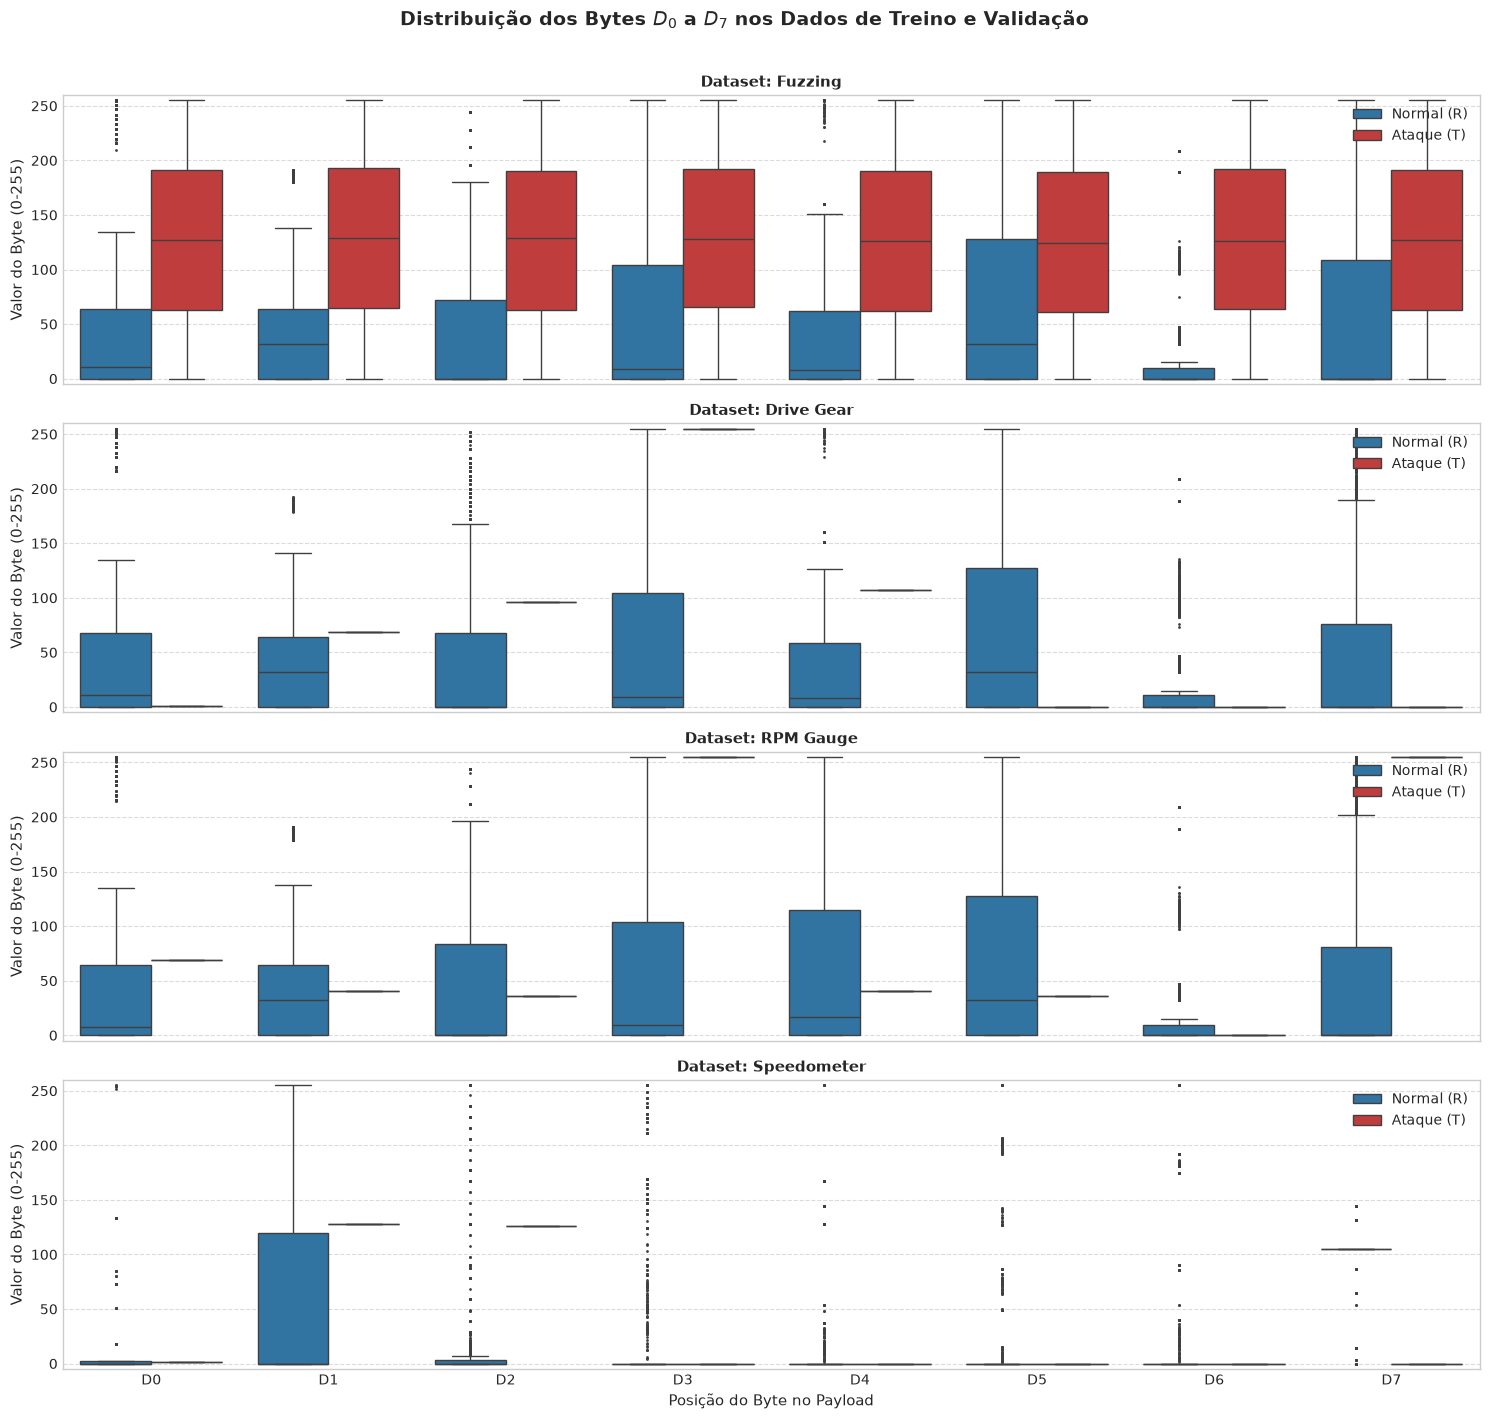

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)
fig.suptitle(r'Distribuição dos Bytes $D_0$ a $D_7$ nos Dados de Treino e Validação', y=1.01, fontsize=14, fontweight='bold')

for i, (name, df_tv) in enumerate(dfs_train_val.items()):
    ax = axes[i]
    df_r = df_tv[df_tv['Flag'] == 'R'].sample(min(5000, (df_tv['Flag'] == 'R').sum()), random_state=42)
    df_t = df_tv[df_tv['Flag'] == 'T'].sample(min(5000, (df_tv['Flag'] == 'T').sum()), random_state=42)
    df_plot = pd.concat([df_r, df_t])
    
    df_melt = pd.melt(df_plot, id_vars=['Flag'], value_vars=utils.BYTE_COLS, var_name='Byte', value_name='Valor')
    df_melt['Classe'] = df_melt['Flag'].map({'R': 'Normal (R)', 'T': 'Ataque (T)'})
    
    sns.boxplot(data=df_melt, x='Byte', y='Valor', hue='Classe', palette=PALETTE, ax=ax, fliersize=1)
    ax.set_title(f"Dataset: {name}", fontweight='bold', fontsize=11)
    ax.set_ylabel('Valor do Byte (0-255)')
    ax.set_ylim(-5, 260)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    if i < 3:
        ax.set_xlabel('')
    else:
        ax.set_xlabel('Posição do Byte no Payload')
    ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

### 7. Projeção Dimensional com PCA dos Payloads Normalizados
Para inspecionar a separabilidade geométrica dos dados no espaço normalizado ($D_0 \dots D_7 / 255.0 \in [0.0, 1.0]$), aplicamos a **Análise de Componentes Principais (PCA)** sobre as amostras de Treino e Validação:
- O tráfego normal forma uma variedade compacta e restrita, ditada pelos estados físicos possíveis dos componentes mecânicos e elétricos do veículo.
- Os ataques caem completamente fora dessa distribuição, criando uma fronteira nítida para algoritmos de detecção de anomalia baseados em densidade e isolamento.

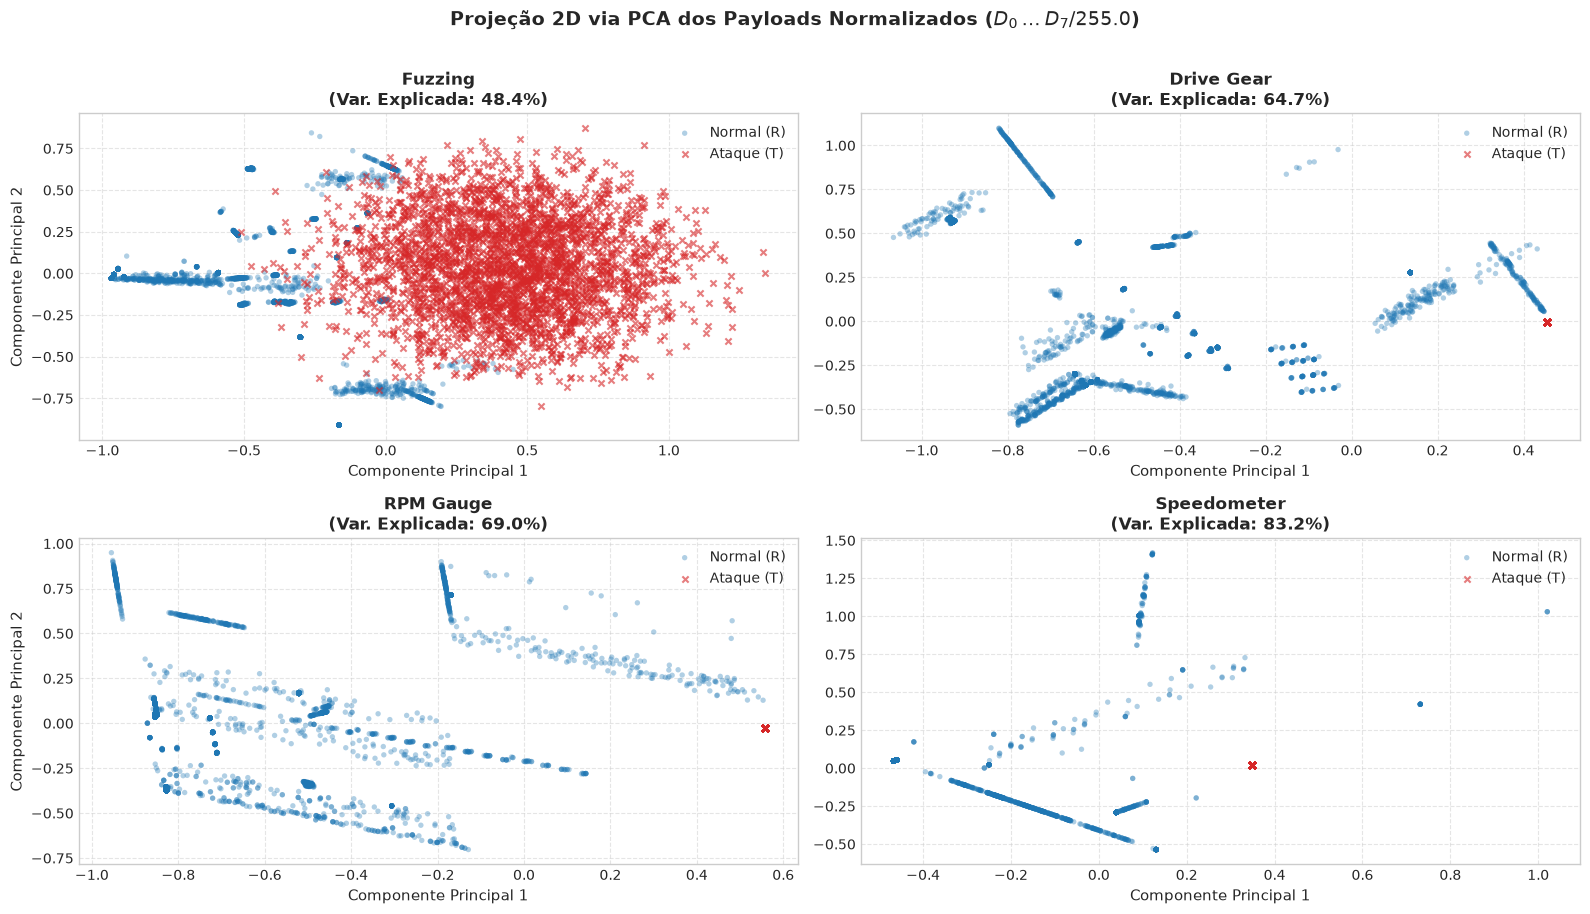

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
axes = axes.flatten()
fig.suptitle(r'Projeção 2D via PCA dos Payloads Normalizados ($D_0 \dots D_7 / 255.0$)', y=1.01, fontweight='bold')

for i, (name, df_tv) in enumerate(dfs_train_val.items()):
    ax = axes[i]
    df_r = df_tv[df_tv['Flag'] == 'R'].sample(min(3000, (df_tv['Flag'] == 'R').sum()), random_state=42)
    df_t = df_tv[df_tv['Flag'] == 'T'].sample(min(3000, (df_tv['Flag'] == 'T').sum()), random_state=42)
    df_sub = pd.concat([df_r, df_t])
    
    # Colunas normalizadas já calculadas pelo utils.py
    X_norm = df_sub[utils.NORM_BYTE_COLS].values
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_norm)
    var_exp = pca.explained_variance_ratio_.sum() * 100
    
    mask_r = (df_sub['Flag'] == 'R').values
    mask_t = (df_sub['Flag'] == 'T').values
    
    ax.scatter(X_pca[mask_r, 0], X_pca[mask_r, 1], c=COLOR_NORMAL, label='Normal (R)', alpha=0.35, s=15, edgecolors='none')
    ax.scatter(X_pca[mask_t, 0], X_pca[mask_t, 1], c=COLOR_ATTACK, label='Ataque (T)', alpha=0.6, s=20, marker='x')
    
    ax.set_title(f"{name}\n(Var. Explicada: {var_exp:.1f}%)", fontweight='bold')
    ax.set_xlabel('Componente Principal 1')
    if i % 2 == 0:
        ax.set_ylabel('Componente Principal 2')
    ax.legend(loc='best')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 7.1 Anatomia Específica do 2º Dataset: *Speedometer Spoofing* (Painel Volkswagen)
No conjunto **Speedometer** (`Prototype/spoofing_speedometer.log`, analisado estritamente sobre as $27.500$ amostras de Treino+Validação):
- O identificador alvo é o `0x05A0` (velocímetro do painel de instrumentos Volkswagen), que responde por $6{,}31\%$ ($1.578$ de $25.000$) dos quadros normais de 8 bytes no conjunto de treino/validação.
- Ao comparar os quadros normais de `0x05A0` com os quadros de ataque (`01 80 7e 00 00 00 00 00`):
  - **Bytes $D_0 = 1$ (`0x01`) e $D_1 = 128$ (`0x80`)**: São **100% idênticos e constantes** tanto nos quadros normais de `0x05A0` quanto nos quadros de ataque! Isso implica que com **$N=1$ ou $N=2$ bytes (`1F` e `2F`)**, o ataque colide exatamente com o tráfego normal de `0x05A0` ($6{,}31\%$ do barramento).
  - **Byte $D_2$ (3º byte — Velocidade)**: No tráfego urbano normal (controlado pelo joystick), $D_2$ varia apenas no intervalo $[0, 28]$ (`0x00` a `0x1C`, média $4{,}81 \pm 7{,}92$). Já no ataque de *spoofing* (220 km/h), $D_2 = 126$ (`0x7E`), completamente disjunto do suporte normal!
  - **Bytes $D_3 \dots D_7 = 0$ (`0x00`)**: São todos nulos tanto nos quadros normais de `0x05A0` quanto no ataque, de modo que a discriminação da anomalia nasce exatamente em **$N \ge 3$ bytes**.

In [9]:
df_spd = dfs_train_val['Speedometer']
norm_all = df_spd[df_spd['Flag'] == 'R']
norm_5a0 = norm_all[norm_all['CAN_ID'] == '05a0']
atk_5a0 = df_spd[df_spd['Flag'] == 'T']

print("=== Estatísticas dos Bytes no ID 0x05A0 (Treino + Validação) ===")
summary_5a0 = pd.DataFrame({
    'Normal (Todos IDs) - Média': norm_all[utils.BYTE_COLS].mean().round(2),
    'Normal (ID 0x05A0) - Min': norm_5a0[utils.BYTE_COLS].min(),
    'Normal (ID 0x05A0) - Média': norm_5a0[utils.BYTE_COLS].mean().round(2),
    'Normal (ID 0x05A0) - Max': norm_5a0[utils.BYTE_COLS].max(),
    'Ataque (ID 0x05A0) - Fixo': atk_5a0[utils.BYTE_COLS].iloc[0]
})
display(summary_5a0)

# Taxa de colisão exata do prefixo de ataque [D0..D_{N-1}] no tráfego normal de Treino+Validação
target_vals = atk_5a0[utils.BYTE_COLS].iloc[0].values
print("\nTaxa de Colisão do Prefixo do Ataque (01 80 7E 00...) no Tráfego Normal (25.000 quadros):")
for n_b in range(1, 9):
    cols_n = utils.BYTE_COLS[:n_b]
    matches = (norm_all[cols_n].values == target_vals[:n_b]).all(axis=1).sum()
    pct = (matches / len(norm_all)) * 100.0
    print(f" -> N={n_b} bytes ({cols_n[-1]} incluído): {matches:5d} / {len(norm_all):,} quadros normais idênticos ({pct:.2f}%)")

=== Estatísticas dos Bytes no ID 0x05A0 (Treino + Validação) ===


,Normal (Todos IDs) - Média,Normal (ID 0x05A0) - Min,Normal (ID 0x05A0) - Média,Normal (ID 0x05A0) - Max,Ataque (ID 0x05A0) - Fixo
D0,4.22,1,1.00,1,1
D1,45.40,128,128.00,128,128
D2,13.12,0,4.81,28,126
D3,7.96,0,0.00,0,0
D4,2.96,0,0.00,0,0
D5,4.75,0,0.00,0,0
D6,4.62,0,0.00,0,0
D7,88.49,0,0.00,0,0



Taxa de Colisão do Prefixo do Ataque (01 80 7E 00...) no Tráfego Normal (25.000 quadros):
 -> N=1 bytes (D0 incluído):  1616 / 25,000 quadros normais idênticos (6.46%)
 -> N=2 bytes (D1 incluído):  1578 / 25,000 quadros normais idênticos (6.31%)
 -> N=3 bytes (D2 incluído):     0 / 25,000 quadros normais idênticos (0.00%)
 -> N=4 bytes (D3 incluído):     0 / 25,000 quadros normais idênticos (0.00%)
 -> N=5 bytes (D4 incluído):     0 / 25,000 quadros normais idênticos (0.00%)
 -> N=6 bytes (D5 incluído):     0 / 25,000 quadros normais idênticos (0.00%)
 -> N=7 bytes (D6 incluído):     0 / 25,000 quadros normais idênticos (0.00%)
 -> N=8 bytes (D7 incluído):     0 / 25,000 quadros normais idênticos (0.00%)


### 8. Validação Cruzada de 10 Folds para Treinamento e Otimização
Para otimizar os hiperparâmetros de forma robusta e sem overfitting, o artigo aplica uma **Validação Cruzada de 10 Folds**:
- As $250.000$ amostras normais são divididas em 10 blocos de $25.000$ amostras.
- Em cada fold $k \in \{0,\dots,9\}$:
  - **Treino**: 9 folds ($225.000$ amostras normais).
  - **Validação**: 1 fold ($25.000$ normais) $+ 25.000$ amostras de ataque (total de $50.000$ amostras balanceadas).

A função `utils.get_kfold_cv_indices()` implementa esse gerador diretamente sobre os índices cacheados, pronta para ser usada nos scripts de treinamento.

In [10]:
# Demonstração do particionador K-Fold em utils.py
for dname in ['Fuzzing', 'Speedometer']:
    sp = splits_info[dname]
    cfg = utils._get_split_config(dname)
    part_atk = bool(cfg['partition_val_attacks_across_folds'])
    print(f"\nEstrutura da Validação Cruzada de 10 Folds — Dataset: {dname}:")
    for fold in range(3):
        tr_idx, val_idx = utils.get_kfold_cv_indices(
            sp['train_val_normal_idx'], sp['val_attack_idx'],
            fold_idx=fold, random_state=42,
            partition_val_attacks_across_folds=part_atk
        )
        print(f" -> Fold {fold + 1}/10: Treino = {len(tr_idx):,} amostras (100% normal) | Validação = {len(val_idx):,} amostras (50% normal + 50% ataque)")
    print("   ... (demais 7 folds seguem a mesma regra de rotação)")


Estrutura da Validação Cruzada de 10 Folds — Dataset: Fuzzing:
 -> Fold 1/10: Treino = 225,000 amostras (100% normal) | Validação = 50,000 amostras (50% normal + 50% ataque)
 -> Fold 2/10: Treino = 225,000 amostras (100% normal) | Validação = 50,000 amostras (50% normal + 50% ataque)
 -> Fold 3/10: Treino = 225,000 amostras (100% normal) | Validação = 50,000 amostras (50% normal + 50% ataque)
   ... (demais 7 folds seguem a mesma regra de rotação)

Estrutura da Validação Cruzada de 10 Folds — Dataset: Speedometer:
 -> Fold 1/10: Treino = 22,500 amostras (100% normal) | Validação = 500 amostras (50% normal + 50% ataque)
 -> Fold 2/10: Treino = 22,500 amostras (100% normal) | Validação = 500 amostras (50% normal + 50% ataque)
 -> Fold 3/10: Treino = 22,500 amostras (100% normal) | Validação = 500 amostras (50% normal + 50% ataque)
   ... (demais 7 folds seguem a mesma regra de rotação)


### 9. Conclusões da EDA e Diretrizes para o Cluster HPC
#### 📌 Principais Conclusões:
1. **Blindagem Metodológica**: A análise exploratória foi conduzida **estritamente sobre Treino e Validação**, mantendo os $>3{,}5$ milhões de frames de Teste intocados para avaliação justa.
2. **Modularização em `utils.py`**: Funções de carregamento, indexação, particionamento e cálculo de métricas agora residem em [utils.py](utils.py), garantindo consistência entre a EDA e os scripts de modelagem.
3. **Assinaturas Distintas e $N=5$ Bytes**:
   - O tráfego legítimo concentra-se em variedades estritas com períodos regulares de $\sim 10\text{ ms}$.
   - Os ataques de spoofing concentram-se em alvos únicos (`0x043F` e `0x0316`), com injeções a cada $\sim 1.1\text{ ms}$ e payloads estáticos.
   - Os primeiros bytes ($D_0 \dots D_4$) já contêm divergência categórica em relação ao tráfego normal, justificando a escolha de $N=5$ bytes para prevenção precoce em $<80\text{ }\mu\text{s}$.

#### 🚀 Próximos Passos para Replicação e Submissão no Cluster:
- Criar script de treinamento em lote (`train_models.py`) importando `utils.py`.
- Utilizar `joblib` para paralelizar o treinamento dos 16 modelos ($8\text{ OCSVM} + 8\text{ iForest}$) nos núcleos de CPU do nó do cluster via SLURM.
- Avaliar os modelos no conjunto de Teste blindado utilizando `utils.load_test_data()` e `utils.evaluate_detection_metrics()`.